In [2]:
import matplotlib.pyplot as plt
from collections import defaultdict
import numpy as np
import stim

import os 

while 'honeycomb.py' not in os.listdir():
    os.chdir("..")

from sims import build_circuit, check_circuit, run_experiment

In [3]:
# c = build_circuit(ncols=5, nrows=3, config_filepath="config/5x3.json", bases=["Z", "X"])
# c.diagram("detslice-svg")
result = run_experiment(ncols=5, nrows=3, config_filepath="config/5x3.json", max_shots=2_000_000)
print(result)

shots: 2000000
logical error rate (any logical): 0.00209  [95% CI 0.002028, 0.002155]  (4181 failures)
  Z logical: 0.000868  (1736 failures)
  X logical: 0.001334  (2667 failures)


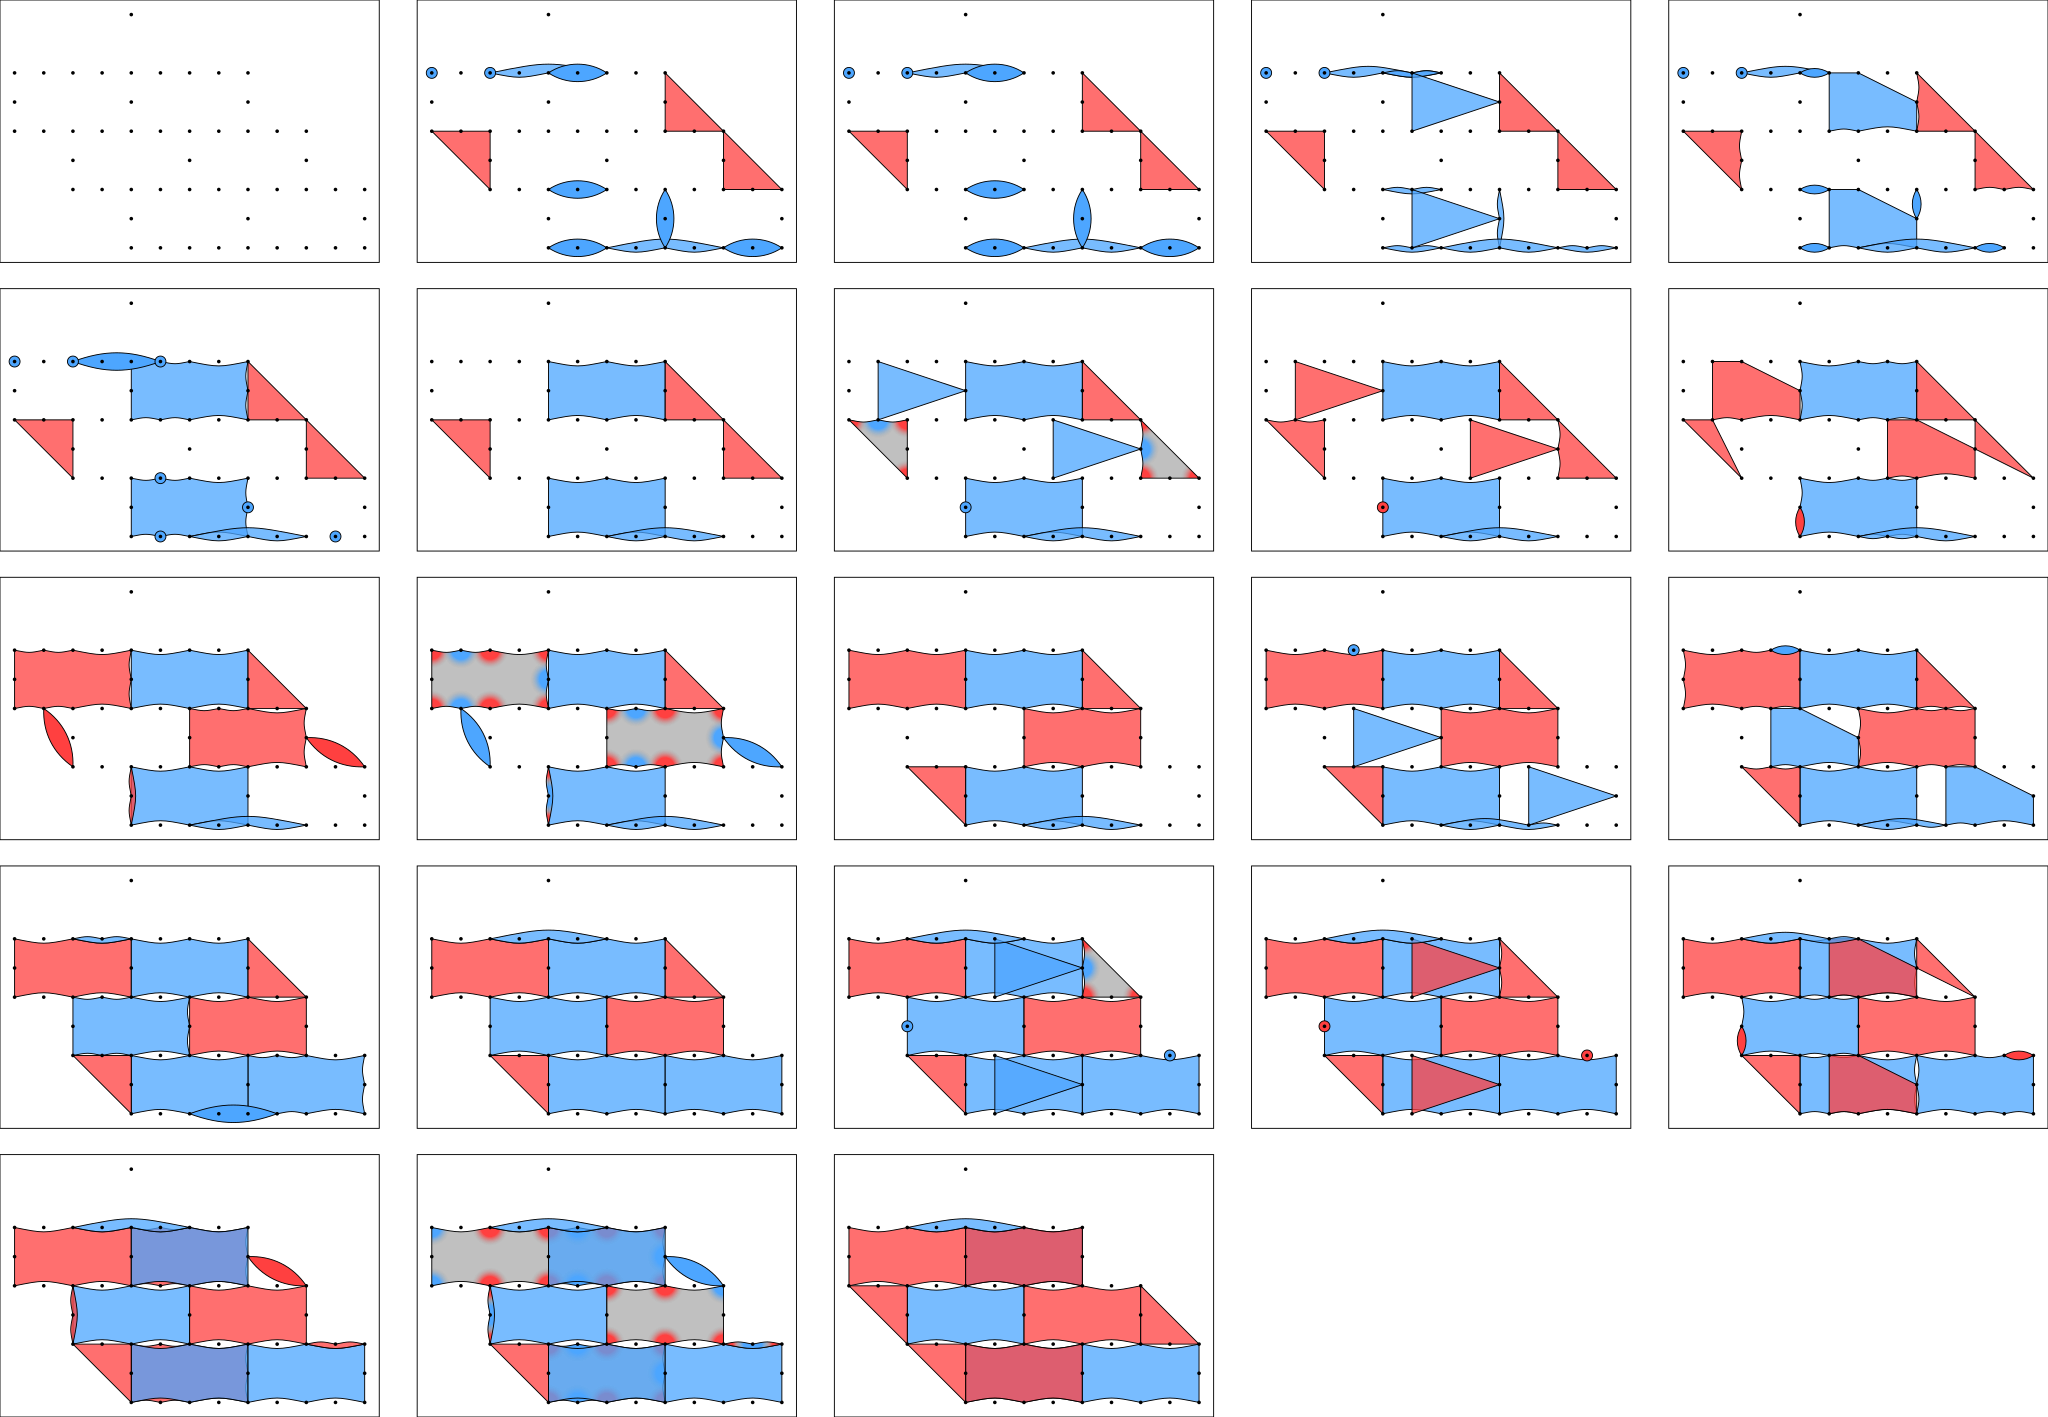

In [4]:
c = build_circuit(ncols=5, nrows=4, config_filepath="config/5x4_straight_logicals.json")
c.diagram("detslice-svg")
# result = run_experiment(ncols=5, nrows=4, config_filepath="config/5x4_testing.json", max_shots=2_000_000)
# print(result)

In [5]:
result = run_experiment(ncols=5, nrows=4, config_filepath="config/5x4.json", max_shots=2_000_000)
print(result)

shots: 2000000
logical error rate (any logical): 0.002083  [95% CI 0.002021, 0.002147]  (4166 failures)
  Z logical: 0.001043  (2085 failures)
  X logical: 0.001134  (2268 failures)


For whatever reason, lengthening the z logical increased the error rate. I imagine this has something to do with those weird 2 body errors but that is a guess.

In [6]:
circuit1 = build_circuit(ncols=5, nrows=4, config_filepath="config/5x4.json")
circuit2 = build_circuit(ncols=5, nrows=4, config_filepath="config/5x4_straight_logicals.json")

In [7]:
def dem_errors(circuit, obs_index=0):
    dem = circuit.detector_error_model(decompose_errors=False,
                                       approximate_disjoint_errors=True,
                                       flatten_loops=True)
    out = []
    for inst in dem.flattened():
        if inst.type != "error":
            continue
        dets = frozenset(t.val for t in inst.targets_copy() if t.is_relative_detector_id())
        obs = sum(1 for t in inst.targets_copy()
                  if t.is_logical_observable_id() and t.val == obs_index) % 2
        out.append((inst.args_copy()[0], dets, obs))
    return out

e1 = dem_errors(circuit1)
e2 = dem_errors(circuit2)

# same detector structure and probabilities?
# assert len(e1) == len(e2)
# assert all(a[1] == b[1] and abs(a[0] - b[0]) < 1e-12 for a, b in zip(e1, e2)), \
#     "DEMs differ in more than the observable"

# build  A w = d  over GF(2): rows = errors, cols = detectors
n_det = circuit1.num_detectors
A = np.zeros((len(e1), n_det), dtype=np.uint8)
d = np.zeros(len(e1), dtype=np.uint8)
for i, (a, b) in enumerate(zip(e1, e2)):
    for k in a[1]:
        A[i, k] = 1
    d[i] = a[2] ^ b[2]

def solvable_gf2(A, d):
    M = np.concatenate([A, d[:, None]], axis=1).copy()
    r = 0
    for c in range(A.shape[1]):
        piv = np.nonzero(M[r:, c])[0]
        if len(piv) == 0:
            continue
        p = piv[0] + r
        M[[r, p]] = M[[p, r]]
        rows = np.nonzero(M[:, c])[0]
        for j in rows:
            if j != r:
                M[j] ^= M[r]
        r += 1
        if r == A.shape[0]:
            break
    # inconsistent if a row is 0 ... 0 | 1
    return not np.any((M[:, :-1].sum(axis=1) == 0) & (M[:, -1] == 1))

print("representatives equivalent under these detectors:", solvable_gf2(A, d))

def dem_map(circuit):
    dem = circuit.detector_error_model(decompose_errors=False,
                                       approximate_disjoint_errors=True,
                                       flatten_loops=True)
    m = defaultdict(float)
    for inst in dem.flattened():
        if inst.type != "error":
            continue
        dets = frozenset(t.val for t in inst.targets_copy() if t.is_relative_detector_id())
        obs = frozenset(t.val for t in inst.targets_copy() if t.is_logical_observable_id())
        p = inst.args_copy()[0]
        k = (dets, obs)
        m[k] = m[k] * (1 - p) + p * (1 - m[k])
    return m

m1, m2 = dem_map(circuit1), dem_map(circuit2)

def by_dets(m):
    out = defaultdict(float)
    for (dets, obs), p in m.items():
        out[dets] = out[dets] * (1 - p) + p * (1 - out[dets])
    return out

b1, b2 = by_dets(m1), by_dets(m2)
print("same detector structure:", b1.keys() == b2.keys())
print("max prob diff:", max(abs(b1[k] - b2[k]) for k in b1.keys() & b2.keys()))

# which detector sets have different observable masks between circuits?
obs1, obs2 = defaultdict(set), defaultdict(set)
for (d, o), p in m1.items(): obs1[d].add(o)
for (d, o), p in m2.items(): obs2[d].add(o)
diff = [d for d in obs1.keys() & obs2.keys() if obs1[d] != obs2[d]]
print(len(diff), "detector sets have different observable masks")

representatives equivalent under these detectors: False
same detector structure: True
max prob diff: 0.0
15 detector sets have different observable masks


In [8]:
def dem_map(circuit):
    dem = circuit.detector_error_model(decompose_errors=False,
                                       approximate_disjoint_errors=True,
                                       flatten_loops=True)
    m = defaultdict(float)
    for inst in dem.flattened():
        if inst.type != "error":
            continue
        dets = frozenset(t.val for t in inst.targets_copy() if t.is_relative_detector_id())
        obs = frozenset(t.val for t in inst.targets_copy() if t.is_logical_observable_id())
        p = inst.args_copy()[0]
        k = (dets, obs)
        m[k] = m[k] * (1 - p) + p * (1 - m[k])
    return m

m1, m2 = dem_map(circuit1), dem_map(circuit2)

def by_dets(m):
    out = defaultdict(float)
    for (dets, obs), p in m.items():
        out[dets] = out[dets] * (1 - p) + p * (1 - out[dets])
    return out

b1, b2 = by_dets(m1), by_dets(m2)
print("same detector structure:", b1.keys() == b2.keys())
print("max prob diff:", max(abs(b1[k] - b2[k]) for k in b1.keys() & b2.keys()))

# which detector sets have different observable masks between circuits?
obs1, obs2 = defaultdict(set), defaultdict(set)
for (d, o), p in m1.items(): obs1[d].add(o)
for (d, o), p in m2.items(): obs2[d].add(o)
diff = [d for d in obs1.keys() & obs2.keys() if obs1[d] != obs2[d]]
print(len(diff), "detector sets have different observable masks")

same detector structure: True
max prob diff: 0.0
15 detector sets have different observable masks


In [9]:
n = circuit1.num_detectors
shots = 3 * n + 500
d1, o1 = circuit1.compile_detector_sampler(seed=7).sample(shots, separate_observables=True)
d2, o2 = circuit2.compile_detector_sampler(seed=7).sample(shots, separate_observables=True)
print("identical detection events:", (d1 == d2).all())
diff_obs = (o1 ^ o2)[:, 0].astype(np.uint8)
print("covered by detectors:", solvable_gf2(d1.astype(np.uint8), diff_obs))

identical detection events: True
covered by detectors: True


In [10]:
import sinter

tasks = [
    sinter.Task(circuit=circuit1, json_metadata={"rep": 1}),
    sinter.Task(circuit=circuit2, json_metadata={"rep": 2}),
]
stats = sinter.collect(
    num_workers=4,
    tasks=tasks,
    decoders=["pymatching"],
    max_shots=1_000_000,
    max_errors=1000,
)
for s in stats:
    print(s.json_metadata, s.errors, s.shots, s.errors / s.shots)

{'rep': 1} 1036 283170 0.0036585796517992725
{'rep': 2} 1649 596036 0.002766611412733459


In [11]:
def decomposed(circuit):
    dem = circuit.detector_error_model(decompose_errors=True,
                                       ignore_decomposition_failures=True,
                                       flatten_loops=True)
    return [str(i) for i in dem.flattened() if i.type == "error" and "^" in str(i)]

h1, h2 = decomposed(circuit1), decomposed(circuit2)
print(len(h1), len(h2))
# strip probabilities and compare the decompositions
strip = lambda s: s.split(")", 1)[1].strip()
s1, s2 = {strip(x) for x in h1}, {strip(x) for x in h2}
print(len(s1 - s2), "decompositions only in circuit1")
print(len(s2 - s1), "decompositions only in circuit2")
for x in list(s1 ^ s2)[:10]:
    print(x)

77 76
25 decompositions only in circuit1
24 decompositions only in circuit2
D12 ^ D20 L0 ^ D13 L0
D16 ^ D15 L0 ^ D13 L0
D16 L1 ^ D13 L0 ^ D11
D13 D15 ^ D14 ^ D16
D16 L1 ^ D13 L0
D12 ^ D20
D12 L1 ^ D13
D13 D15 L0 ^ D16
D13 D15 ^ D14 ^ D12 L1
D16 ^ D15 L0 ^ D13


In [12]:
for k in range(o1.shape[1]):
    diff_k = (o1 ^ o2)[:, k].astype(np.uint8)
    print(f"L{k} covered:", solvable_gf2(d1.astype(np.uint8), diff_k))

L0 covered: True
L1 covered: True


In [13]:
import sinter
from stimbposd import sinter_decoders

stats = sinter.collect(
    num_workers=4,
    tasks=[sinter.Task(circuit=circuit1, json_metadata={"rep": 1}),
           sinter.Task(circuit=circuit2, json_metadata={"rep": 2})],
    decoders=["bposd"],
    custom_decoders=sinter_decoders(),
    max_shots=1_000_000,
    max_errors=1000,
)
for s in stats:
    print(s.json_metadata, s.errors / s.shots)

{'rep': 2} 0.004391497628861111
{'rep': 1} 0.004611115916667221


In [14]:
from decoding import run_experiment, make_tasks, collect, format_results, to_results

In [15]:
results = run_experiment(
    ncols=5,
    nrows=4,
    decoders=("pymatching", "pymatching-correlated", "bposd"),
    config_filepath="config/5x4_straight_logicals.json",
    max_shots=2_000_000, 
    max_errors=5000,
)
print(*results)


results = run_experiment(
    ncols=5,
    nrows=4,
    decoders=("pymatching", "pymatching-correlated", "bposd"),
    config_filepath="config/5x4.json",
    max_shots=2_000_000, 
    max_errors=5000
)
print(*results)

pymatching             any   0.00228  [95% CI 0.002215, 0.002347]  (4560/2000000) pymatching-correlated  any   0.002787  [95% CI 0.002715, 0.002862]  (5490/1969741) bposd                  any   0.004447  [95% CI 0.004336, 0.00456]  (6000/1349290)
pymatching             any   0.002096  [95% CI 0.002033, 0.00216]  (4191/2000000) pymatching-correlated  any   0.003658  [95% CI 0.003569, 0.00375]  (6251/1708851) bposd                  any   0.004405  [95% CI 0.004296, 0.004517]  (6083/1381034)


In [16]:
tasks = (make_tasks(circuit1, ("pymatching", "pymatching-correlated", "bposd"), metadata={"rep": 1})
       + make_tasks(circuit2, ("pymatching", "pymatching-correlated", "bposd"), metadata={"rep": 2}))
stats = collect(tasks, max_shots=2_000_000, max_errors=5000)
print(format_results(to_results(stats)))

pymatching             any   0.002066  [95% CI 0.002004, 0.002129]  (4131/2000000) {'rep': 1}
pymatching-correlated  any   0.002788  [95% CI 0.002716, 0.002862]  (5569/1997649) {'rep': 2}
bposd                  any   0.004426  [95% CI 0.004314, 0.004541]  (5812/1313109) {'rep': 1}
pymatching             any   0.002344  [95% CI 0.002277, 0.002411]  (4687/2000000) {'rep': 2}
pymatching-correlated  any   0.003675  [95% CI 0.003581, 0.003772]  (5678/1545011) {'rep': 1}
bposd                  any   0.004404  [95% CI 0.004293, 0.004517]  (5909/1341781) {'rep': 2}


In [17]:
from testing.codespace_distance import build_circuit as build_circuit_codespace

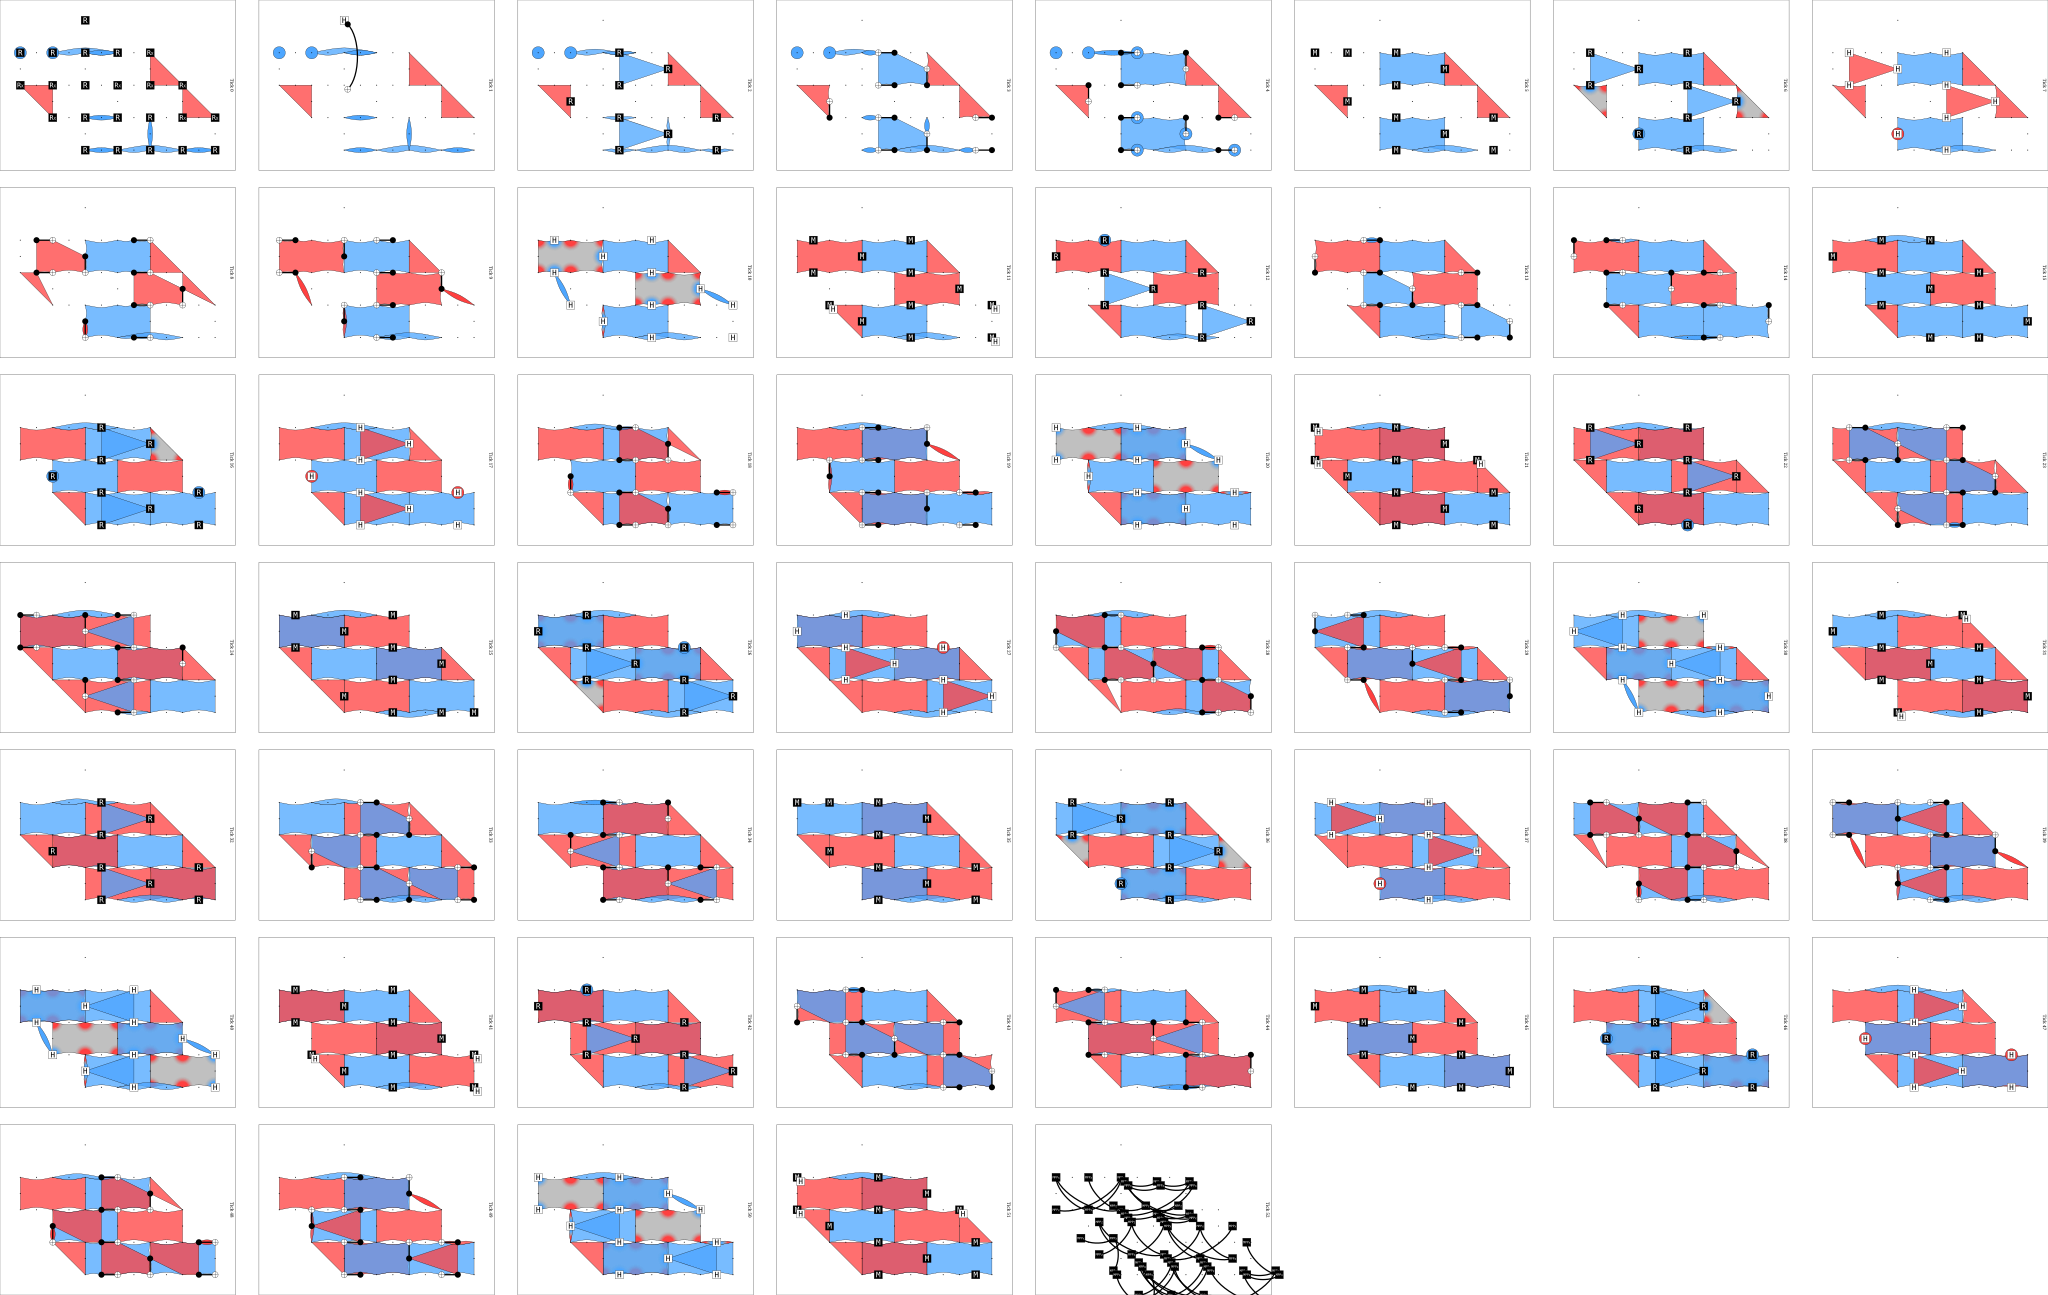

In [18]:
c = build_circuit_codespace(ncols=5, nrows=4, config="5x4_straight_logicals.json")
c.without_noise().diagram("detslice-with-ops-svg")

In [19]:
err = c.shortest_graphlike_error()
print(len(err))

2


should be a method to check for missing detectors in beta stim, increase number of rounds and if the number of mising detectors increases then we are missing detectors

In [20]:
print(err)

[stim.ExplainedError(dem_error_terms=(stim.DemTargetWithCoords(dem_target=stim.DemTarget('D19'), coords=[2.25, 0, 35]),), circuit_error_locations=(stim.CircuitErrorLocation(tick_offset=23, flipped_pauli_product=(stim.GateTargetWithCoords(stim.target_x(2), [1, 0]),stim.GateTargetWithCoords(stim.target_x(24), [0.5, 0]),), flipped_measurement=stim.FlippedMeasurement(
    record_index=None,
    observable=(),
), instruction_targets=stim.CircuitTargetsInsideInstruction(gate='DEPOLARIZE2', args=[0.0001], target_range_start=0, target_range_end=2, targets_in_range=(stim.GateTargetWithCoords(2, [1, 0]),stim.GateTargetWithCoords(24, [0.5, 0]),)), stack_frames=(stim.CircuitErrorLocationStackFrame(
    instruction_offset=114,
    iteration_index=0,
    instruction_repetitions_arg=0,
),)),stim.CircuitErrorLocation(tick_offset=23, flipped_pauli_product=(stim.GateTargetWithCoords(stim.target_y(2), [1, 0]),stim.GateTargetWithCoords(stim.target_y(24), [0.5, 0]),), flipped_measurement=stim.FlippedMeasur

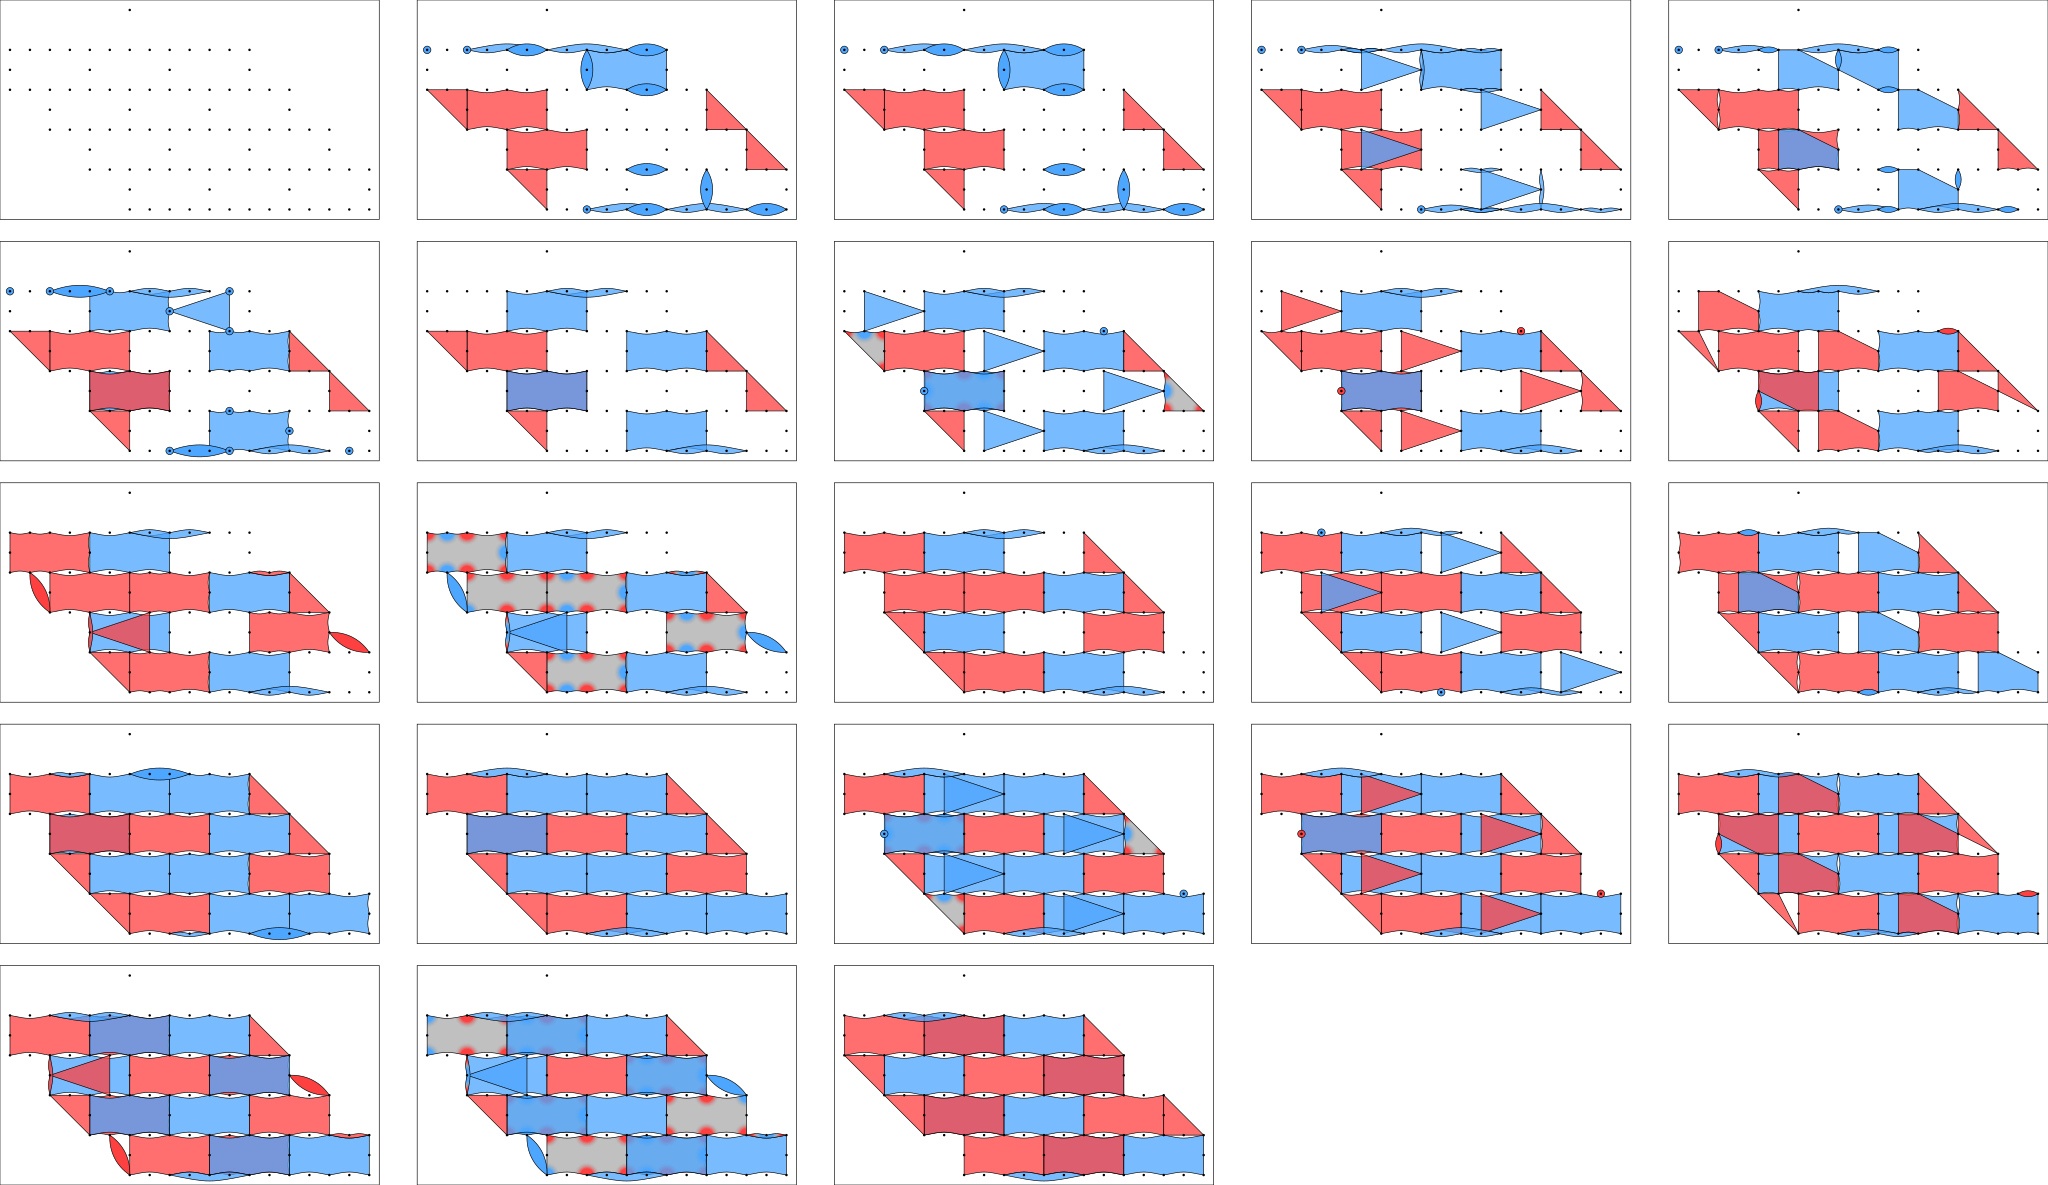

In [21]:
c = build_circuit(ncols=7, nrows=5, config_filepath="config/7x5.json")
c.diagram("detslice-svg")

In [24]:
err = run_experiment(ncols=7, nrows=5, config_filepath="config/7x5.json")
print(*err)

pymatching             any   0.00295  [95% CI 0.002632, 0.003306]  (295/100000)


In [28]:
from testing.codespace_distance import build_circuit as build_circuit_codespace

In [30]:
c = build_circuit_codespace(ncols=7, nrows=5, config="7x5.json")
err = c.shortest_graphlike_error()
print(len(err))

3
